In [1]:
from read_training_data import get_tension_data, get_raw_data, get_lengths, calculate_res_freq
import pandas as pd
import numpy as np

In [ ]:
# training data
raw_data_path = "/vols/dune/sb3423/DWA/training-data/raw/APA_5947a8b0-5152-11ed-84c6-9170f34dd096b_apa4_training"
processed_data_path = "/vols/dune/sb3423/DWA/training-data/processed/5947a8b0-5152-11ed-84c6-9170f34dd096b_apa4_training.json"

proc_scans = get_tension_data(processed_data_path, ["U", "X"])

keys_to_remove = {"scanEndMode", "measuredBy", "stage", "apaUuid", "type"}
raw_scans = get_raw_data(raw_data_path, keys_to_remove)

proc_df = pd.DataFrame(proc_scans)
raw_df = pd.DataFrame(raw_scans)

comb_df = pd.merge(raw_df, proc_df, on="uid", how="outer")

final_comb_df = comb_df.dropna(subset=['tension'])
numeric_tension = pd.to_numeric(final_comb_df['tension'], errors='coerce') # removes tensions that aren't found
final_comb_df['tension'] = numeric_tension

u_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/U_Layer_Tension_Template.xlsx", "U")
x_side_lengths = get_lengths("/vols/dune/sb3423/DWA/training-data/tensions/X_Layer_Tension_Template.xlsx", "X")

final_df = pd.merge(final_comb_df, u_side_lengths, on="uid", how="inner") # this only includes U layer wires

x_wires = final_comb_df[final_comb_df["uid"].str.startswith("X", na=False)]
x_wires["length"] = x_side_lengths

final_df = pd.concat([final_df, x_wires], ignore_index=True) # reincludes X layers

tension = final_df['tension'].values
lengths = final_df['length'].values / 1000 # in meters
rho = 1.52e-4

res_freq = calculate_res_freq(tension, lengths, rho) # in Hz
final_df['res_freq'] = res_freq

In [1]:
from read_training_data import get_tension_data, get_raw_data, get_lengths, calculate_res_freq
import pandas as pd
import numpy as np

# testing new dataset
new_raw_path = "/vols/dune/amh24/APA-DWA-measurements/4ml/scanData/raw/APA_APA30_PostCold_27_01_26/"
new_proc_path = "/vols/dune/amh24/APA-DWA-measurements/4ml/scanData/processed/APA30_PostCold_27_01_26.json"

proc_scans = get_tension_data(new_proc_path, stage="DWA Development")
keys_to_remove = {"scanEndMode", "measuredBy", "apaUuid", "type"}
raw_scans = get_raw_data(new_raw_path, keys_to_remove)

proc_df = pd.DataFrame(proc_scans)
raw_df = pd.DataFrame(raw_scans)

Debug: Found segment GB00439 in layer G, side B.


In [2]:
comb_df = pd.merge(raw_df, proc_df, on=["uid", "parent_folder"], how="outer")
final_comb_df = comb_df.dropna(subset=['tension'])
# final_comb_df.head(3)

In [4]:
u_side_lengths = get_lengths("training-data/tensions/U_Layer_Tension_Template.xlsx", "U")
v_side_lengths = get_lengths("training-data/tensions/V_Layer_Tension_Template.xlsx", "V")
x_side_lengths = get_lengths("training-data/tensions/X_Layer_Tension_Template.xlsx", "X")
g_side_lengths = get_lengths("training-data/tensions/G_Layer_Tension_Template.xlsx", "G")

In [5]:
full_u_df = pd.merge(final_comb_df, u_side_lengths, on="uid", how="inner") # this only includes U layer wires
full_v_df = pd.merge(final_comb_df, v_side_lengths, on="uid", how="inner")

full_x_df = final_comb_df[final_comb_df["uid"].str.startswith("X", na=False)]
full_x_df["length"] = x_side_lengths

full_g_df = final_comb_df[final_comb_df["uid"].str.startswith("G", na=False)]
full_g_df["length"] = g_side_lengths

In [6]:
df_list = [full_u_df, full_v_df, full_x_df, full_g_df]
final_df = pd.concat(df_list, ignore_index=True)

In [7]:
print(final_df.shape)
print(final_comb_df.shape)

(5580, 12)
(5580, 11)


In [9]:
tension = final_df['tension'].values
lengths = final_df['length'].values / 1000 # in meters

rho = 1.52e-4
 
res_freq = calculate_res_freq(tension, lengths, rho) # in Hz

print(res_freq.shape)
final_df['res_freq'] = res_freq

(5580,)


In [10]:
final_df.head(3)

,uid,segment_id,channel_index,freq,ampl,layer,stage,headboardNumber,side,parent_folder,tension,length,res_freq
0,UA100,100,1,"[50.0, 50.125, 50.25, 50.375, 50.5, 50.625, 50...","[1178.724853, 1179.521033, 1180.689301, 1184.1...",U,DWA Development,8,A,20260129T044354_U_A_8_98-100-102-104-106-108-1...,5.780000,976.211629,99.877613
1,UA1000,1000,3,"[50.0, 50.125, 50.25, 50.375, 50.5, 50.625, 50...","[760.903078, 762.459906, 762.105291, 762.87439...",U,DWA Development,6,A,20260129T054237_U_A_6_194-196-198-200-594-596-...,5.769702,1509.017556,64.555105
2,UA1001,1001,0,"[50.0, 50.125, 50.25, 50.375, 50.5, 50.625, 50...","[3185.163432, 3185.545625, 3187.924834, 3194.7...",U,DWA Development,5,A,20260129T072630_U_A_5_201-203-205-207-209-211-...,6.500000,1499.165635,68.969213


array([[<Axes: title={'center': 'res_freq'}>]], dtype=object)

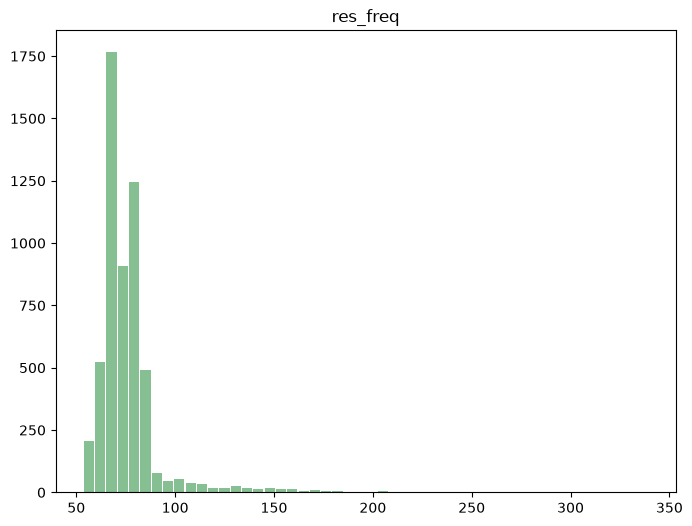

In [ ]:
from matplotlib import pyplot as plt
x_df = final_df[final_df["uid"].str.startswith("X", na=False)]
g_df = final_df[final_df["uid"].str.startswith("G", na=False)]
u_df = final_df[final_df["uid"].str.startswith("U", na=False)]
v_df = final_df[final_df["uid"].str.startswith("V", na=False)]

dfs = [x_df, g_df, u_df, v_df]
fig, ax = plt.subplots(2, 2, figsize=(10, 6))

final_df.hist(column='res_freq', bins=50, grid=False, figsize=(8,6), color='#86bf91', zorder=2, rwidth=0.9)